# Notebook 08: Evaluación y Análisis de Errores

**Objetivo:** Evaluar el MLP entrenado sobre el conjunto de Test reservado, calculando las métricas de clasificación (Accuracy, Precision, Recall, F1 y ROC-AUC), la matriz de confusión y el análisis de falsos positivos/negativos. Se compara además con un modelo base de referencia (Secciones 14 y 16 de la plantilla).

In [1]:
import os
import sys
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)
from sklearn.linear_model import LogisticRegression

# Clonar el repositorio para acceder a la carpeta src (si no existe)
if not os.path.exists('redes-neuronales-riesgo-crediticio'):
    !git clone https://github.com/JuanCardona2203/redes-neuronales-riesgo-crediticio.git

for repo_path in ['/content/redes-neuronales-riesgo-crediticio', '..']:
    if repo_path not in sys.path:
        sys.path.append(repo_path)

from src.model import CreditRiskMLP

In [2]:
# Carga de los datos escalados y del modelo entrenado en 06_training.ipynb
X_train = pd.read_csv('data/processed/X_train_scaled.csv').values
y_train = pd.read_csv('data/processed/y_train.csv').values.ravel()
X_test = pd.read_csv('data/processed/X_test_scaled.csv').values
y_test = pd.read_csv('data/processed/y_test.csv').values.ravel()

model = CreditRiskMLP(input_dim=6)
model.load_state_dict(torch.load('models/mlp_credit_risk.pt'))
model.eval()

# Predicciones del MLP sobre el Test
with torch.no_grad():
    y_prob = model(torch.tensor(X_test, dtype=torch.float32)).numpy().ravel()
y_pred = (y_prob >= 0.5).astype(int)

print('Predicciones generadas sobre el conjunto de Test.')

Predicciones generadas sobre el conjunto de Test.


In [3]:
# Métricas de clasificación del MLP (Sección 14)
metricas = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob),
}
for nombre, valor in metricas.items():
    print(f'{nombre:>10}: {valor:.4f}')

print('\n--- Reporte de clasificación ---')
print(classification_report(y_test, y_pred, target_names=['Cumple (0)', 'Mora (1)']))

  Accuracy: 0.8427
 Precision: 0.6710
    Recall: 0.5478
        F1: 0.6032
   ROC-AUC: 0.8511

--- Reporte de clasificación ---
              precision    recall  f1-score   support

  Cumple (0)       0.88      0.93      0.90      5094
    Mora (1)       0.67      0.55      0.60      1422

    accuracy                           0.84      6516
   macro avg       0.78      0.74      0.75      6516
weighted avg       0.83      0.84      0.84      6516



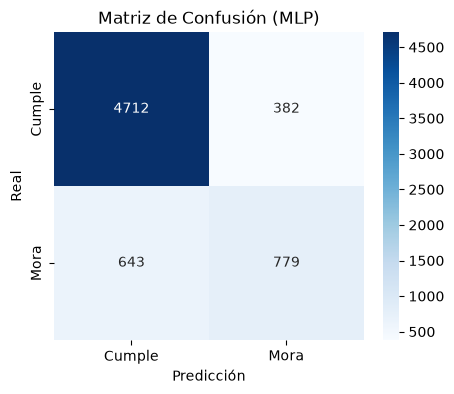

Verdaderos Negativos (TN): 4712
Falsos Positivos (FP):     382
Falsos Negativos (FN):     643
Verdaderos Positivos (TP): 779


In [4]:
# Matriz de confusión (Sección 14)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Cumple', 'Mora'], yticklabels=['Cumple', 'Mora'])
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión (MLP)')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'Verdaderos Negativos (TN): {tn}')
print(f'Falsos Positivos (FP):     {fp}')
print(f'Falsos Negativos (FN):     {fn}')
print(f'Verdaderos Positivos (TP): {tp}')

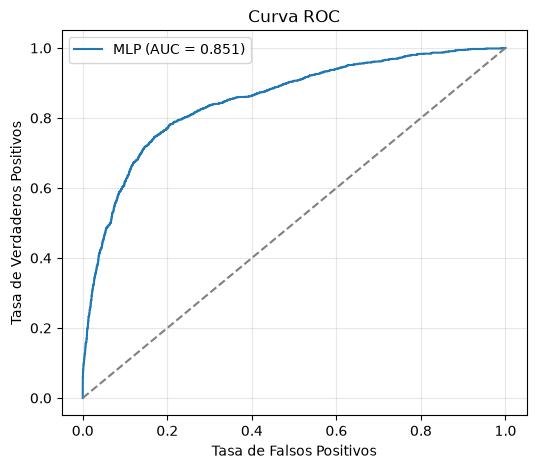

In [5]:
# Curva ROC (Sección 14)
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"MLP (AUC = {metricas['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Análisis de errores (Sección 14)

| Error | Significado en el negocio |
| :--- | :--- |
| **Falso Positivo (FP)** | Se predice mora a un cliente que sí paga → rechazo injustificado (pérdida de cliente solvente). |
| **Falso Negativo (FN)** | Se predice cumplimiento a un cliente que cae en mora → pérdida de capital por incobrabilidad. |

In [6]:
# Comparación con un baseline: Regresión Logística (Sección 16)
logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train, y_train)
lr_prob = logreg.predict_proba(X_test)[:, 1]
lr_pred = (lr_prob >= 0.5).astype(int)

comparacion = pd.DataFrame({
    'Modelo': ['Regresión Logística (baseline)', 'MLP (Red Neuronal)'],
    'Accuracy': [accuracy_score(y_test, lr_pred), metricas['Accuracy']],
    'Precision': [precision_score(y_test, lr_pred), metricas['Precision']],
    'Recall': [recall_score(y_test, lr_pred), metricas['Recall']],
    'F1': [f1_score(y_test, lr_pred), metricas['F1']],
    'ROC-AUC': [roc_auc_score(y_test, lr_prob), metricas['ROC-AUC']],
})
comparacion

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Regresión Logística (baseline),0.831031,0.697904,0.398031,0.506941,0.827039
1,MLP (Red Neuronal),0.842695,0.670973,0.547820,0.603175,0.851077


In [7]:
# Guardar los resultados de evaluación como evidencia (Secciones 14 y 16)
os.makedirs('reports', exist_ok=True)
comparacion.to_csv('reports/comparacion_modelos.csv', index=False)
print('Resultados guardados en reports/comparacion_modelos.csv')

Resultados guardados en reports/comparacion_modelos.csv
